# Structured Assignment 2: Basic Python for Data Analysis
## Topik 2: Customer Churn Analysis & Retention Strategy
**Program Studi:** Sistem Informasi - Universitas Multimedia Nusantara  
**Mata Kuliah:** Data Analysis (IS389)  
**Kelompok 5:**
* Matthew Fernando Sheldon
* Pangeran Natanael Napitupulu
* Asty Felyshia Eka Danastri
* Joyandro Gerard Diasz

**Dataset:** `train.csv` (Kaggle Playground Series S6E3 Reference - 594,194 baris observasi pelanggan)

---

### Daftar Isi:
1. **Penyempurnaan Business & Data Understanding (Review Week 1)**
2. **Implementasi Variabel Python (Domain Churn)**
3. **Penerapan 4 Struktur Data Python (`list`, `tuple`, `set`, `dictionary`)**
4. **Percabangan Logika Bisnis (`if-elif-else`)**
5. **Perulangan Pemrosesan Batch Data (`for` loop)**
6. **Fungsi Kustom Evaluasi Risiko Churn (`def assess_churn_risk`)**
7. **Eksplorasi Skala Besar dengan NumPy, Pandas, & Matplotlib**
8. **Kesimpulan Analitik & Roadmap Menuju Week 3**

---
## 1. Penyempurnaan Business & Data Understanding (Review Week 1)

### A. Business Understanding (Konteks Masalah & Sasaran Bisnis)
* **Masalah Bisnis (*The Business Problem*):**  
  Pada industri berbasis langganan telekomunikasi, *Customer Churn* mengakibatkan penurunan langsung terhadap *Monthly Recurring Revenue* (MRR). Mengakuisisi pelanggan baru (*Customer Acquisition Cost* / CAC) membutuhkan biaya 5 hingga 7 kali lebih tinggi daripada menjaga pelanggan yang sudah ada. Churn yang terjadi di awal masa berlangganan (*early churn*) menyebabkan nilai seumur hidup pelanggan (*Customer Lifetime Value* / CLV) tidak sempat menutupi modal akuisisi.
* **Tujuan Bisnis (*The Business Objective*):**  
  1. Menurunkan laju churn tahunan.  
  2. Melindungi pendapatan berulang dengan memperpanjang rata-rata masa berlangganan (*average tenure*).  
  3. Mengalokasikan anggaran program retensi secara tepat sasaran kepada segmen pelanggan berisiko tinggi (*high-risk*).
* **Tujuan Analisis Data (*Data Analysis Objective*):**  
  Membangun alur kerja analitik data menggunakan Python untuk mendeteksi profil risiko pelanggan secara terotomatisasi, menghitung *revenue at risk*, dan memberikan rekomendasi tindakan penanganan yang preskriptif.

### B. Data Understanding (`train.csv`)
Dataset yang digunakan pada penugasan ini adalah `train.csv` yang memuat **594,194 baris data pelanggan** dengan **20 variabel atribut**:
* **Demografi:** `gender`, `SeniorCitizen`, `Partner`, `Dependents`
* **Layanan Utama:** `tenure`, `PhoneService`, `MultipleLines`, `InternetService`
* **Layanan Nilai Tambah (*Add-ons*):** `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`
* **Kontrak & Finansial:** `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`

---
## 2. Implementasi Variabel Python (Domain Churn)

Variabel digunakan untuk menyimpan nilai titik data pelanggan ke dalam memori komputer dengan berbagai tipe data primitif:
* `str`: Merepresentasikan teks (ID pelanggan, jenis kontrak, metode pembayaran, paket internet).
* `int`: Merepresentasikan bilangan bulat (durasi *tenure* dalam bulan, status biner lansia).
* `float`: Merepresentasikan angka desimal berpresisi (tagihan bulanan, total tagihan, skor probabilitas).
* `bool`: Merepresentasikan kondisi logis `True`/`False` (ketersediaan bantuan teknis, tagihan digital).

In [7]:
# 1. Definisi Variabel Karakteristik Pelanggan
customer_id = "CUST-594194"            # str: ID unik pelanggan
customer_name = "Jane Doe"             # str: Nama pelanggan
contract_type = "Month-to-month"       # str: Jenis kontrak komitmen
internet_type = "Fiber optic"          # str: Jenis teknologi koneksi internet
payment_method = "Electronic check"    # str: Opsi metode pembayaran

tenure_months = 4                      # int: Masa berlangganan dalam satuan bulan
is_senior_citizen = 0                  # int: Indikator lansia (0 = Tidak, 1 = Ya)

monthly_charges = 89.85                # float: Besaran tagihan per bulan ($)
total_charges = 359.40                 # float: Akumulasi tagihan hingga saat ini ($)
churn_score = 0.825                    # float: Estimasi probabilitas risiko churn

has_tech_support = False               # bool: Apakah pelanggan berlangganan Tech Support
has_online_security = False            # bool: Apakah memiliki Online Security
is_paperless_billing = True            # bool: Apakah menggunakan tagihan digital paperless

# 2. Menampilkan informasi variabel dan tipe datanya
print("=== PROFIL DATA PELANGGAN TUNGGAL ===")
print(f"Customer ID        : {customer_id} | Tipe: {type(customer_id).__name__}")
print(f"Tipe Kontrak       : {contract_type} | Tipe: {type(contract_type).__name__}")
print(f"Tenure Pelanggan   : {tenure_months} bulan | Tipe: {type(tenure_months).__name__}")
print(f"Tagihan Bulanan    : ${monthly_charges:.2f} | Tipe: {type(monthly_charges).__name__}")
print(f"Tech Support Aktif : {has_tech_support} | Tipe: {type(has_tech_support).__name__}")
print(f"Paperless Billing  : {is_paperless_billing} | Tipe: {type(is_paperless_billing).__name__}")

=== PROFIL DATA PELANGGAN TUNGGAL ===
Customer ID        : CUST-594194 | Tipe: str
Tipe Kontrak       : Month-to-month | Tipe: str
Tenure Pelanggan   : 4 bulan | Tipe: int
Tagihan Bulanan    : $89.85 | Tipe: float
Tech Support Aktif : False | Tipe: bool
Paperless Billing  : True | Tipe: bool


**Interpretasi Bisnis:**  
Variabel di atas menggambarkan profil pelanggan baru (*tenure* baru 4 bulan) dengan kontrak fleksibel bulanan (*Month-to-month*) dan tagihan relatif tinggi ($89.85/bulan) pada koneksi Fiber Optic tanpa perlindungan *Tech Support*. Kombinasi parameter ini secara empiris menempatkan pelanggan pada zona risiko churn sangat tinggi.

---
## 3. Penerapan 4 Struktur Data Python (`list`, `tuple`, `set`, `dictionary`)

Struktur data memungkinkan pengorganisasian data yang lebih kompleks dan terstruktur:
1. **`list` (Daftar):** Terurut, dapat diubah (*mutable*), mengizinkan elemen duplikat.
2. **`tuple` (Tupel):** Terurut, tidak dapat diubah (*immutable*), menjamin integritas data referensi.
3. **`set` (Himpunan):** Tidak berurutan, elemen unik (tanpa duplikasi), mendukung operasi himpunan (irisan, selisih).
4. **`dictionary` (Kamus):** Pasangan kunci-nilai (*key-value*), pencarian cepat $O(1)$, ideal untuk model objek data pelanggan.

In [8]:
# 1. LIST: Faktor Pemicu Churn & Sampel Tagihan Bulanan
churn_risk_factors = [
    "Month-to-month Contract",
    "Tenure <= 12 months",
    "High Monthly Charges (> $75)",
    "No Tech Support",
    "Electronic Check Payment"
]
sample_monthly_charges = [29.85, 56.95, 74.40, 89.85, 105.20]

print("--- 1. LIST ---")
print(f"Daftar faktor risiko churn : {churn_risk_factors}")
print(f"Jumlah faktor risiko       : {len(churn_risk_factors)}")
print(f"Faktor prioritas teratas   : '{churn_risk_factors[0]}'")
print(f"Rata-rata sampel tagihan   : ${sum(sample_monthly_charges) / len(sample_monthly_charges):.2f}")

# 2. TUPLE: Kategori Baku Tingkat Risiko (Immutable) & Snapshot Pelanggan
CHURN_RISK_LEVELS = ("Low Risk", "Medium Risk", "High Risk")
customer_record = (594194, "Month-to-month", 4, 89.85)

print("\n--- 2. TUPLE ---")
print(f"Kategori Baku Risiko Churn : {CHURN_RISK_LEVELS}")
cust_id, c_contract, c_tenure, c_charge = customer_record
print(f"Unpacked Pelanggan -> ID: {cust_id}, Kontrak: {c_contract}, Tenure: {c_tenure} bln, Tagihan: ${c_charge}")

# 3. SET: Himpunan Opsi Pembayaran & Layanan Keamanan (Operasi Himpunan)
all_payment_methods = {"Electronic check", "Mailed check", "Bank transfer", "Credit card"}
all_security_addons = {"OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"}
customer_current_addons = {"DeviceProtection", "StreamingTV"}

missing_addons = all_security_addons.difference(customer_current_addons)

print("\n--- 3. SET ---")
print(f"Katalog Metode Pembayaran (Unik) : {all_payment_methods}")
print(f"Total Layanan Proteksi Tersedia   : {all_security_addons}")
print(f"Layanan Proteksi Aktif Pelanggan  : {customer_current_addons}")
print(f"Peluang Cross-Selling / Bundling : {missing_addons}")

# 4. DICTIONARY: Representasi Customer 360 View
customer_360 = {
    "id": 594194,
    "demographics": {"gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No"},
    "tenure": 4,
    "services": {
        "InternetService": "Fiber optic",
        "OnlineSecurity": "No",
        "TechSupport": "No",
        "StreamingTV": "Yes"
    },
    "billing": {
        "Contract": "Month-to-month",
        "PaymentMethod": "Electronic check",
        "MonthlyCharges": 89.85,
        "TotalCharges": 359.40
    }
}

print("\n--- 4. DICTIONARY ---")
print(f"ID Pelanggan      : {customer_360['id']}")
print(f"Layanan Internet  : {customer_360['services']['InternetService']}")
print(f"Durasi Langganan  : {customer_360['tenure']} bulan")
print(f"Tagihan Bulanan   : ${customer_360['billing']['MonthlyCharges']}")

--- 1. LIST ---
Daftar faktor risiko churn : ['Month-to-month Contract', 'Tenure <= 12 months', 'High Monthly Charges (> $75)', 'No Tech Support', 'Electronic Check Payment']
Jumlah faktor risiko       : 5
Faktor prioritas teratas   : 'Month-to-month Contract'
Rata-rata sampel tagihan   : $71.25

--- 2. TUPLE ---
Kategori Baku Risiko Churn : ('Low Risk', 'Medium Risk', 'High Risk')
Unpacked Pelanggan -> ID: 594194, Kontrak: Month-to-month, Tenure: 4 bln, Tagihan: $89.85

--- 3. SET ---
Katalog Metode Pembayaran (Unik) : {'Mailed check', 'Bank transfer', 'Credit card', 'Electronic check'}
Total Layanan Proteksi Tersedia   : {'OnlineSecurity', 'DeviceProtection', 'OnlineBackup', 'TechSupport'}
Layanan Proteksi Aktif Pelanggan  : {'DeviceProtection', 'StreamingTV'}
Peluang Cross-Selling / Bundling : {'OnlineSecurity', 'TechSupport', 'OnlineBackup'}

--- 4. DICTIONARY ---
ID Pelanggan      : 594194
Layanan Internet  : Fiber optic
Durasi Langganan  : 4 bulan
Tagihan Bulanan   : $89.85


---
## 4. Percabangan Logika Bisnis (`if-elif-else`) & Perulangan (`for` loop)

Dalam praktiknya, tim *Customer Success* memerlukan sistem penapisan otomatis untuk menentukan tingkatan urgensi intervensi pelanggan:
* **`if - elif - else`:** Mengklasifikasikan tingkat risiko pelanggan berdasarkan variabel prediktor (tipe kontrak, *tenure*, besaran tagihan bulanan, ketiadaan *tech support*).
* **`for` loop:** Melakukan pemrosesan secara berulang terhadap sekumpulan pelanggan dalam satu *batch*, menghitung total pendapatan yang terancam (*Monthly Recurring Revenue at Risk*).

In [9]:
# Contoh batch data pelanggan dalam bentuk list of dictionaries
customer_batch = [
    {"id": 101, "Contract": "Month-to-month", "tenure": 3,  "MonthlyCharges": 89.50, "TechSupport": "No"},
    {"id": 102, "Contract": "Two year",       "tenure": 48, "MonthlyCharges": 65.00, "TechSupport": "Yes"},
    {"id": 103, "Contract": "Month-to-month", "tenure": 8,  "MonthlyCharges": 95.20, "TechSupport": "No"},
    {"id": 104, "Contract": "One year",       "tenure": 24, "MonthlyCharges": 50.10, "TechSupport": "Yes"},
    {"id": 105, "Contract": "Month-to-month", "tenure": 18, "MonthlyCharges": 72.80, "TechSupport": "Yes"},
]

risk_counts = {"High Risk": 0, "Medium Risk": 0, "Low Risk": 0}
total_mrr_at_risk = 0.0

print(f"{'ID':<6} | {'Contract':<15} | {'Tenure':<8} | {'Monthly $':<10} | {'Risk Status':<12} | {'Action Priority'}")
print("-" * 75)

# Perulangan for memproses setiap data pelanggan
for cust in customer_batch:
    c_id = cust["id"]
    c_contract = cust["Contract"]
    c_tenure = cust["tenure"]
    c_charge = cust["MonthlyCharges"]
    c_support = cust["TechSupport"]
    
    # Percabangan Logika Aturan Bisnis
    if c_contract == "Month-to-month" and c_tenure <= 12 and c_support == "No":
        risk_status = "High Risk"
        priority = "P1 - Critical Alert"
        action = "Outreach segera: berikan promo diskon transisi kontrak tahunan & gratis Tech Support"
    elif c_contract == "Month-to-month" and (c_tenure > 12 or c_charge >= 70.0):
        risk_status = "Medium Risk"
        priority = "P2 - Retention Offer"
        action = "Kirim voucher bundling proteksi perangkat & sarankan auto-debit"
    else:
        risk_status = "Low Risk"
        priority = "P3 - Healthy/Loyal"
        action = "Jaga hubungan: tawarkan program loyalitas & diskon renewal"
        
    risk_counts[risk_status] += 1
    if risk_status in ["High Risk", "Medium Risk"]:
        total_mrr_at_risk += c_charge
        
    print(f"{c_id:<6} | {c_contract:<15} | {c_tenure:<3} bulan | ${c_charge:<9.2f} | {risk_status:<12} | {priority}")

print("-" * 75)
print("=== RINGKASAN MONITORING BATCH ===")
for level, count in risk_counts.items():
    print(f"  * {level:<12} : {count} pelanggan")
print(f"  * Total MRR Terancam Risiko Churn : ${total_mrr_at_risk:.2f} / bulan (${total_mrr_at_risk * 12:.2f} / tahun)")

ID     | Contract        | Tenure   | Monthly $  | Risk Status  | Action Priority
---------------------------------------------------------------------------
101    | Month-to-month  | 3   bulan | $89.50     | High Risk    | P1 - Critical Alert
102    | Two year        | 48  bulan | $65.00     | Low Risk     | P3 - Healthy/Loyal
103    | Month-to-month  | 8   bulan | $95.20     | High Risk    | P1 - Critical Alert
104    | One year        | 24  bulan | $50.10     | Low Risk     | P3 - Healthy/Loyal
105    | Month-to-month  | 18  bulan | $72.80     | Medium Risk  | P2 - Retention Offer
---------------------------------------------------------------------------
=== RINGKASAN MONITORING BATCH ===
  * High Risk    : 2 pelanggan
  * Medium Risk  : 1 pelanggan
  * Low Risk     : 2 pelanggan
  * Total MRR Terancam Risiko Churn : $257.50 / bulan ($3090.00 / tahun)


---
## 5. Fungsi Kustom Evaluasi Risiko Churn (`def assess_churn_risk`)

Fungsi (*function*) memungkinkan modularitas, penggunaan ulang kode (*code reusability*), dan pemisahan logika bisnis yang rapi.  
Fungsi `assess_churn_risk` menerima dictionary profil pelanggan, mengevaluasi parameter kunci, dan mengembalikan dictionary hasil diagnosis lengkap dengan rekomendasi tindakan spesifik.

In [10]:
def assess_churn_risk(customer_data: dict) -> dict:
    """
    Mengevaluasi tingkat risiko churn pelanggan telekomunikasi berdasarkan
    tipe kontrak, tenure, besaran tagihan bulanan, dan kepemilikan tech support.
    """
    tenure = customer_data.get("tenure", 0)
    contract = customer_data.get("Contract", "Month-to-month")
    monthly_charge = float(customer_data.get("MonthlyCharges", 0.0))
    tech_support = customer_data.get("TechSupport", "No")
    
    # Skoring Aturan Bisnis
    if contract == "Month-to-month" and tenure <= 12 and tech_support == "No":
        risk_level = "High Risk"
        risk_score = 88.0
        tier = "Critical (P1)"
        action = "Intervensi Proaktif CS: Tawarkan insentif diskon 25% kontrak 1-tahun + paket free Tech Support 6 bulan."
    elif contract == "Month-to-month" and (tenure > 12 or monthly_charge >= 70.0):
        risk_level = "Medium Risk"
        risk_score = 55.0
        tier = "Moderate (P2)"
        action = "Program Retensi CRM: Edukasi penggunaan add-on proteksi dan insentif beralih ke Auto-Debit."
    elif contract in ["One year", "Two year"] and tenure <= 12:
        risk_level = "Medium Risk"
        risk_score = 35.0
        tier = "Monitoring (P3)"
        action = "Onboarding Touchpoint: Hubungi untuk survei kepuasan layanan awal (CSAT) dan optimasi jaringan."
    else:
        risk_level = "Low Risk"
        risk_score = 12.0
        tier = "Stable (P4)"
        action = "Loyalty Nurturing: Masukkan dalam program VIP reward dan penawaran bundling smart home."
        
    annual_loss_estimate = monthly_charge * 12 if risk_level == "High Risk" else monthly_charge * 6
    
    return {
        "customer_id": customer_data.get("id", "Unknown"),
        "risk_level": risk_level,
        "risk_score": risk_score,
        "urgency_tier": tier,
        "monthly_charges": monthly_charge,
        "potential_annual_loss": annual_loss_estimate,
        "recommended_strategy": action
    }

# Pengujian fungsi dengan profil pelanggan berbeda
sample_a = {"id": 594194, "tenure": 3, "Contract": "Month-to-month", "MonthlyCharges": 95.50, "TechSupport": "No"}
sample_b = {"id": 612800, "tenure": 60, "Contract": "Two year", "MonthlyCharges": 55.00, "TechSupport": "Yes"}

for cust, desc in [(sample_a, "Pelanggan Baru Risiko Tinggi"), (sample_b, "Pelanggan Lama Loyal")]:
    res = assess_churn_risk(cust)
    print(f"=== HASIL SKORING: {desc} (ID: {res['customer_id']}) ===")
    print(f"  * Status Risiko       : {res['risk_level']} (Skor: {res['risk_score']} / 100)")
    print(f"  * Tingkat Urgensi     : {res['urgency_tier']}")
    print(f"  * Tagihan Bulanan     : ${res['monthly_charges']:.2f}")
    print(f"  * Potensi Kerugian/Th : ${res['potential_annual_loss']:.2f}")
    print(f"  * Rekomendasi Aksi    : {res['recommended_strategy']}\n")

=== HASIL SKORING: Pelanggan Baru Risiko Tinggi (ID: 594194) ===
  * Status Risiko       : High Risk (Skor: 88.0 / 100)
  * Tingkat Urgensi     : Critical (P1)
  * Tagihan Bulanan     : $95.50
  * Potensi Kerugian/Th : $1146.00
  * Rekomendasi Aksi    : Intervensi Proaktif CS: Tawarkan insentif diskon 25% kontrak 1-tahun + paket free Tech Support 6 bulan.

=== HASIL SKORING: Pelanggan Lama Loyal (ID: 612800) ===
  * Status Risiko       : Low Risk (Skor: 12.0 / 100)
  * Tingkat Urgensi     : Stable (P4)
  * Tagihan Bulanan     : $55.00
  * Potensi Kerugian/Th : $330.00
  * Rekomendasi Aksi    : Loyalty Nurturing: Masukkan dalam program VIP reward dan penawaran bundling smart home.



---
## 6. Eksplorasi Skala Besar dengan NumPy, Pandas, & Matplotlib

### Peran Ketiga Pustaka dalam Proyek Churn:
1. **NumPy (`numpy`):**  
   Pustaka komputasi numerik berkinerja tinggi yang menyediakan struktur data `ndarray`. Berguna untuk komputasi statistik cepat (rata-rata, median, deviasi standar, persentil) dan operasi vektorisasi tanpa overhead perulangan Python standar.
2. **Pandas (`pandas`):**  
   Pustaka utama manajemen dan manipulasi data tabular (`DataFrame` & `Series`). Digunakan untuk membaca dataset `test.csv` (254.655 baris), pengecekan nilai kosong (*missing values*), penyaringan segmen data, dan agregasi statistik grup (`groupby`).
3. **Matplotlib (`matplotlib.pyplot`):**  
   Pustaka dasar visualisasi data di Python. Digunakan untuk membuat grafik histogram sebaran *tenure*, diagram batang proporsi tipe kontrak, dan grafik kotak (*boxplot*) sebaran tagihan guna mengomunikasikan temuan data ke pemangku kepentingan.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Konfigurasi gaya grafik Matplotlib
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
%matplotlib inline

# Mencari jalur file train.csv secara fleksibel
possible_paths = [
    "../data/raw/train.csv",
    "data/raw/train.csv",
    "Week02/data/raw/train.csv",
    "Week01/data/raw/train.csv",
    "../../Week01/data/raw/train.csv",
    "./train.csv",
]
dataset_file = next((p for p in possible_paths if os.path.exists(p)), None)

if dataset_file is None:
    raise FileNotFoundError("File train.csv tidak ditemukan di direktori yang diperiksa.")

print(f"Memuat dataset dari: {dataset_file} ...")
df_test = pd.read_csv(dataset_file)
print("Dataset berhasil dimuat!")
print(f"Dimensi Data: {df_test.shape[0]:,} baris x {df_test.shape[1]} kolom")

Memuat dataset dari: ./train.csv ...
Dataset berhasil dimuat!
Dimensi Data: 594,194 baris x 21 kolom


In [5]:
# 1. Inspeksi 5 Baris Teratas dan Info Tipe Data Kolom
print("5 Baris Teratas Dataset train.csv:")
display(df_test.head(5))

print("\nRingkasan Informasi Struktur Kolom:")
df_test.info()

5 Baris Teratas Dataset train.csv:


,id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,Male,0,Yes,Yes,29,Yes,No,DSL,Yes,...,Yes,Yes,No,No,One year,Yes,Mailed check,60.10,1653.85,No
1,1,Male,0,Yes,Yes,58,Yes,No,DSL,Yes,...,No,Yes,Yes,No,Two year,No,Credit card (automatic),69.50,3778.20,No
2,2,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.40,5841.35,No
3,3,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.70,70.70,Yes
4,4,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.45,70.45,Yes



Ringkasan Informasi Struktur Kolom:
<class 'pandas.DataFrame'>
RangeIndex: 594194 entries, 0 to 594193
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                594194 non-null  int64  
 1   gender            594194 non-null  str    
 2   SeniorCitizen     594194 non-null  int64  
 3   Partner           594194 non-null  str    
 4   Dependents        594194 non-null  str    
 5   tenure            594194 non-null  int64  
 6   PhoneService      594194 non-null  str    
 7   MultipleLines     594194 non-null  str    
 8   InternetService   594194 non-null  str    
 9   OnlineSecurity    594194 non-null  str    
 10  OnlineBackup      594194 non-null  str    
 11  DeviceProtection  594194 non-null  str    
 12  TechSupport       594194 non-null  str    
 13  StreamingTV       594194 non-null  str    
 14  StreamingMovies   594194 non-null  str    
 15  Contract          594194 non-null  str    

In [13]:
# 2. Pengecekan Missing Values (Nilai Kosong)
missing_summary = df_test.isnull().sum()
print("Jumlah Missing Values per Kolom:")
print(missing_summary[missing_summary > 0] if missing_summary.sum() > 0 else "Seluruh kolom bersih: 0 Missing Values!")

Jumlah Missing Values per Kolom:
Seluruh kolom bersih: 0 Missing Values!


In [14]:
# 3. Komputasi Statistik Numerik Menggunakan NumPy
tenure_arr = df_test["tenure"].dropna().to_numpy()
monthly_arr = df_test["MonthlyCharges"].dropna().to_numpy()
total_arr = df_test["TotalCharges"].dropna().to_numpy()

print("=== STATISTIK NUMERIK DENGAN NUMPY ===")
print("Masa Berlangganan (Tenure - Bulan):")
print(f"  * Mean (Rata-rata)   : {np.mean(tenure_arr):.2f} bulan")
print(f"  * Median             : {np.median(tenure_arr):.2f} bulan")
print(f"  * Standar Deviasi    : {np.std(tenure_arr):.2f} bulan")
print(f"  * Min - Max          : {np.min(tenure_arr)} - {np.max(tenure_arr)} bulan")

print("\nTagihan Bulanan (Monthly Charges - $):")
print(f"  * Mean (Rata-rata)   : ${np.mean(monthly_arr):.2f}")
print(f"  * Median             : ${np.median(monthly_arr):.2f}")
print(f"  * Standar Deviasi    : ${np.std(monthly_arr):.2f}")
print(f"  * Kuartil 25% - 75%  : ${np.percentile(monthly_arr, 25):.2f} - ${np.percentile(monthly_arr, 75):.2f}")

=== STATISTIK NUMERIK DENGAN NUMPY ===
Masa Berlangganan (Tenure - Bulan):
  * Mean (Rata-rata)   : 36.58 bulan
  * Median             : 35.00 bulan
  * Standar Deviasi    : 25.06 bulan
  * Min - Max          : 1 - 72 bulan

Tagihan Bulanan (Monthly Charges - $):
  * Mean (Rata-rata)   : $65.87
  * Median             : $74.10
  * Standar Deviasi    : $31.07
  * Kuartil 25% - 75%  : $29.90 - $90.80


In [15]:
# 4. Analisis Frekuensi dan Agregasi dengan Pandas
print("Distribusi Tipe Kontrak (Pandas value_counts):")
contract_counts = df_test["Contract"].value_counts()
contract_shares = df_test["Contract"].value_counts(normalize=True) * 100
summary_table = pd.DataFrame({
    "Jumlah Pelanggan": contract_counts,
    "Proporsi (%)": contract_shares.round(2)
})
display(summary_table)

print("\nRata-rata Tagihan Bulanan per Tipe Kontrak (Pandas groupby):")
contract_group = df_test.groupby("Contract")["MonthlyCharges"].agg(["count", "mean", "median", "std"]).round(2)
display(contract_group)

Distribusi Tipe Kontrak (Pandas value_counts):


,Jumlah Pelanggan,Proporsi (%)
Contract,,
Month-to-month,298918,50.31
Two year,186943,31.46
One year,108333,18.23



Rata-rata Tagihan Bulanan per Tipe Kontrak (Pandas groupby):


,count,mean,median,std
Contract,,,,
Month-to-month,298918,71.26,75.70,25.20
One year,108333,63.73,65.70,33.37
Two year,186943,58.48,61.25,36.10


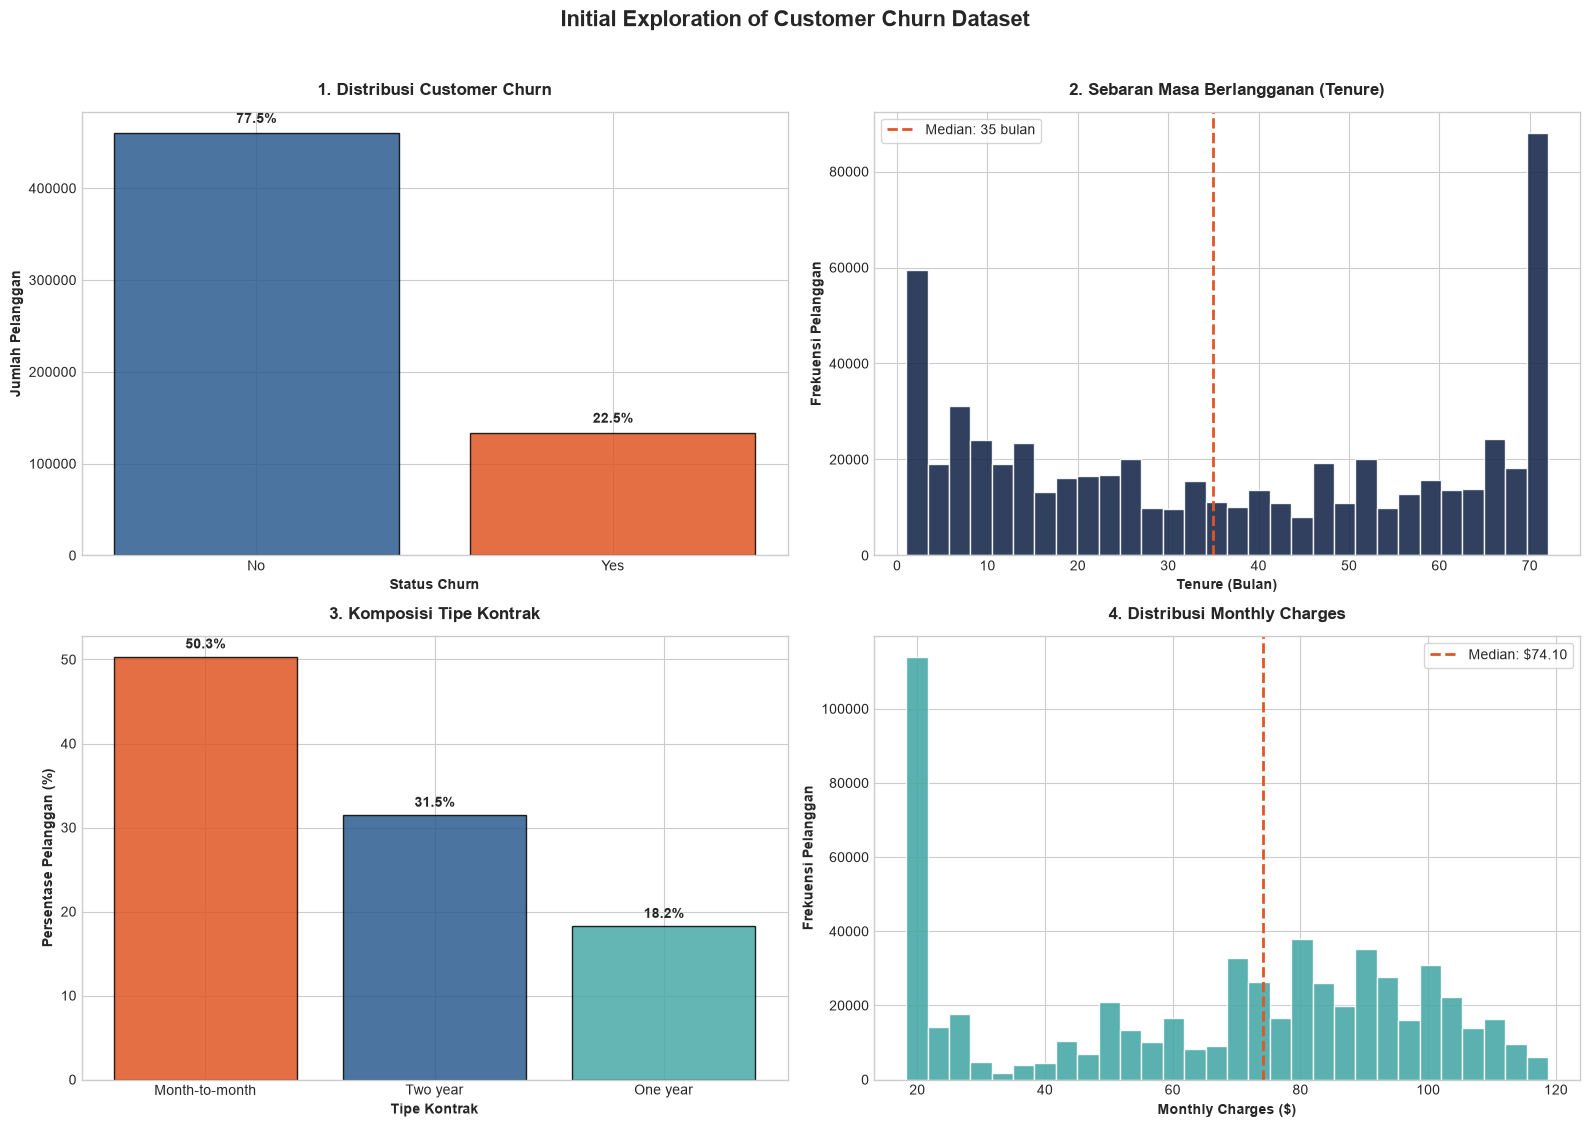

In [7]:
# 5. Visualisasi Empat Aspek Utama Menggunakan Matplotlib

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Warna utama
main_color = "#1A2B4C"
accent_color = "#E05624"
secondary_color = "#2B5C8F"
third_color = "#48A9A6"


# ==========================================================
# 1. Distribusi Churn
# ==========================================================

churn_counts = df_test["Churn"].value_counts()
churn_percentages = (
    df_test["Churn"]
    .value_counts(normalize=True)
    .mul(100)
)

churn_colors = [secondary_color, accent_color]

bars = axes[0, 0].bar(
    churn_counts.index,
    churn_counts.values,
    color=churn_colors,
    edgecolor="black",
    alpha=0.85
)

axes[0, 0].set_title(
    "1. Distribusi Customer Churn",
    fontsize=12,
    fontweight="bold",
    pad=12
)

axes[0, 0].set_xlabel("Status Churn", fontweight="bold")
axes[0, 0].set_ylabel("Jumlah Pelanggan", fontweight="bold")

# Menampilkan persentase di atas bar
for bar, status in zip(bars, churn_counts.index):
    percentage = churn_percentages[status]

    axes[0, 0].annotate(
        f"{percentage:.1f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontweight="bold"
    )


# ==========================================================
# 2. Distribusi Tenure
# ==========================================================

axes[0, 1].hist(
    tenure_arr,
    bins=30,
    color=main_color,
    edgecolor="white",
    alpha=0.9
)

median_tenure = np.median(tenure_arr)

axes[0, 1].axvline(
    median_tenure,
    color=accent_color,
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_tenure:.0f} bulan"
)

axes[0, 1].set_title(
    "2. Sebaran Masa Berlangganan (Tenure)",
    fontsize=12,
    fontweight="bold",
    pad=12
)

axes[0, 1].set_xlabel("Tenure (Bulan)", fontweight="bold")
axes[0, 1].set_ylabel("Frekuensi Pelanggan", fontweight="bold")

axes[0, 1].legend(frameon=True)


# ==========================================================
# 3. Komposisi Tipe Kontrak
# ==========================================================

contracts = contract_shares.index.tolist()
percentages = contract_shares.values.tolist()

contract_colors = [
    accent_color,
    secondary_color,
    third_color
]

bars = axes[1, 0].bar(
    contracts,
    percentages,
    color=contract_colors,
    edgecolor="black",
    alpha=0.85
)

axes[1, 0].set_title(
    "3. Komposisi Tipe Kontrak",
    fontsize=12,
    fontweight="bold",
    pad=12
)

axes[1, 0].set_xlabel("Tipe Kontrak", fontweight="bold")
axes[1, 0].set_ylabel("Persentase Pelanggan (%)", fontweight="bold")

for bar in bars:
    yval = bar.get_height()

    axes[1, 0].annotate(
        f"{yval:.1f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            yval
        ),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontweight="bold"
    )


# ==========================================================
# 4. Distribusi Monthly Charges
# ==========================================================

axes[1, 1].hist(
    monthly_arr,
    bins=30,
    color=third_color,
    edgecolor="white",
    alpha=0.9
)

median_monthly = np.median(monthly_arr)

axes[1, 1].axvline(
    median_monthly,
    color=accent_color,
    linestyle="--",
    linewidth=2,
    label=f"Median: ${median_monthly:.2f}"
)

axes[1, 1].set_title(
    "4. Distribusi Monthly Charges",
    fontsize=12,
    fontweight="bold",
    pad=12
)

axes[1, 1].set_xlabel(
    "Monthly Charges ($)",
    fontweight="bold"
)

axes[1, 1].set_ylabel(
    "Frekuensi Pelanggan",
    fontweight="bold"
)

axes[1, 1].legend(frameon=True)


# ==========================================================
# Final Layout
# ==========================================================

plt.suptitle(
    "Initial Exploration of Customer Churn Dataset",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

os.makedirs("../reports/figures", exist_ok=True)

plt.savefig(
    "../reports/figures/01_customer_churn_initial_overview.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

---
## 7. Kesimpulan Awal & Roadmap Menuju Week 3

### Kesimpulan Awal
Berdasarkan proses data understanding dan eksplorasi awal terhadap dataset `train.csv`, diperoleh beberapa poin utama:

1. Dataset terdiri dari **594.194 data pelanggan dan 21 variabel**, yang mencakup informasi demografi pelanggan, layanan yang digunakan, jenis kontrak, metode pembayaran, biaya pelanggan, serta variabel target **`Churn`**.

2. Berdasarkan distribusi target, sebanyak **77,48% pelanggan tidak mengalami churn**, sedangkan **22,52% pelanggan mengalami churn**. Hal ini menunjukkan bahwa sebagian besar pelanggan masih bertahan, tetapi jumlah pelanggan yang churn tetap cukup signifikan untuk dianalisis lebih lanjut.

3. Distribusi **tenure** menunjukkan adanya pelanggan dengan masa berlangganan yang beragam, mulai dari pelanggan baru hingga pelanggan yang telah menggunakan layanan dalam jangka waktu panjang.

4. Variabel **Contract** terdiri dari tiga kategori utama, yaitu `Month-to-month`, `One year`, dan `Two year`. Perbedaan komposisi jenis kontrak ini dapat menjadi salah satu aspek yang dianalisis lebih lanjut terkait perilaku churn pelanggan.

5. Distribusi **MonthlyCharges** menunjukkan adanya variasi biaya bulanan yang cukup luas antar pelanggan. Variabel ini nantinya dapat digunakan untuk melihat apakah terdapat pola tertentu antara besarnya biaya bulanan dan keputusan pelanggan untuk berhenti menggunakan layanan.

Secara keseluruhan, eksplorasi awal menunjukkan bahwa dataset memiliki informasi yang cukup untuk mendukung analisis customer churn. Namun, visualisasi pada tahap ini masih bersifat **deskriptif dan memberikan gambaran awal dataset**, sehingga belum dapat digunakan untuk menyimpulkan faktor penyebab churn.

Analisis selanjutnya dapat dilakukan dengan membandingkan variabel seperti `Contract`, `tenure`, `MonthlyCharges`, `TechSupport`, dan `PaymentMethod` terhadap status `Churn` untuk mengidentifikasi pola yang lebih spesifik.

### Rencana Kerja Week 3 (Persiapan Pemodelan Lanjutan):
* Melakukan *data preprocessing* (encoding variabel kategorik seperti `InternetService`, `Contract`, `PaymentMethod`).
* Rekayasa fitur (*feature engineering*): rasio tagihan bulanan terhadap total tagihan (`MonthlyCharges / TotalCharges`), serta indeks kelengkapan add-on proteksi.
* Membangun model klasifikasi prediktif machine learning (Logistic Regression, Random Forest, XGBoost) untuk menghasilkan probabilitas churn individual yang presisi.